# Proyecto Final Integrador: Proceso KDD para la Detección Automatizada de Fraude en Tarjetas de Crédito (Dataset 2026)

**Autor:** Roberto Alejandro Chagra Martínez (Código: `208447128`)  
**Materia:** Minería de Datos y Descubrimiento de Conocimiento (*Data Mining & Knowledge Discovery*)  
**Institución:** Centro Universitario de Guadalajara (CUGDL) — Universidad de Guadalajara  
**Base de Datos:** `credit_card_fraud_detection_2026.csv` (`100,000` registros $\times$ `43` variables)

---

## 1. Etapa 1 del Proceso KDD: Definición del Objetivo y Comprensión del Dominio

### 1.1 Planteamiento del Problema
El ecosistema global de pagos digitales procesa millones de operaciones por minuto donde las transacciones fraudulentas representan una fracción estadística mínima frente al volumen legítimo. Este proyecto aborda el **descubrimiento de patrones de comportamiento anómalos y reglas de decisión interpretables** que permitan la detección automatizada de fraude mediante técnicas de Minería de Datos aplicando de extremo a extremo el proceso **Knowledge Discovery in Databases (KDD)**.

### 1.2 Objetivos Analíticos y de Negocio
* **Objetivo de Negocio:** Minimizar la pérdida financiera por fraude transaccional (que asciende a **\$279,842.20 USD** en la muestra analizada) reduciendo la omisión de fraudes (*Falsos Negativos*) sin bloquear excesivamente la operatoria legítima de los tarjetahabientes (*Falsos Positivos*).
* **Objetivo Técnico de Minería de Datos:** Combinar **Detección No Supervisada de Valores Atípicos** (*IQR de Tukey* e *Isolation Forest*), **Ingeniería y Selección Estadística de Características** ($\chi^2$ e importancia Gini), **Balanceo Sintético de Clases (*SMOTE*)** y **Clasificación Supervisada Comparativa** (*Dummy Baseline*, *Regresión Logística*, *Árbol de Decisión*, *Random Forest* y *Gradient Boosting*), culminando con la extracción de **Reglas de Decisión Accionables**.


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import chi2
from sklearn.ensemble import IsolationForest, RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

# Carga del dataset local
posibles_rutas = [
    Path('../Datasets/credit_card_fraud_detection_2026.csv'),
    Path('Datasets/credit_card_fraud_detection_2026.csv'),
    Path('credit_card_fraud_detection_2026.csv'),
]
ruta_csv = next((p for p in posibles_rutas if p.exists()), posibles_rutas[0])
df_raw = pd.read_csv(ruta_csv)

print(f"Dimensiones originales del dataset: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
display(df_raw.head(5))

Dimensiones originales del dataset: 100,000 filas x 43 columnas


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


### Análisis de la Carga Inicial y Estructura del Esquema
La inspección inicial confirma un volumen masivo de **`100,000` transacciones** y **`43` atributos** heterogéneos que integran señales de monto (`transaction_amount`), velocidad transaccional (`transactions_last_1h`, `transactions_last_24h`, `amount_last_1h`), geolocalización (`distance_from_home_km`, `distance_from_last_tx_km`, `international_transaction`, `high_risk_country`), seguridad física (`card_present`, `used_chip`, `used_pin`), perfil crediticio (`credit_score`, `credit_limit`, `account_age_days`) y comportamiento histórico (`avg_transaction_amount_30d`, `num_declined_last_30d`, `num_chargebacks_ever`).

---
## 2. Etapa 2 del Proceso KDD: Selección de Datos y Auditoría contra *Data Leakage*

Antes de construir cualquier modelo, es indispensable analizar la distribución de la variable objetivo (`is_fraud`), perfilar las modalidades de fraude registradas y auditar qué columnas representan **identificadores administrativos** o **fuga de información (*Data Leakage*)**.

=== Distribución de la Variable Objetivo (is_fraud) ===
Clase 0 (Legítima):    97,945 transacciones (97.945%)
Clase 1 (Fraudulenta): 2,055 transacciones (2.055%)
Razón de desbalance:   1 fraude por cada 47.66 transacciones legítimas
Pérdida económica total por fraude: $279,842.20 USD (Promedio por fraude: $136.18 USD)


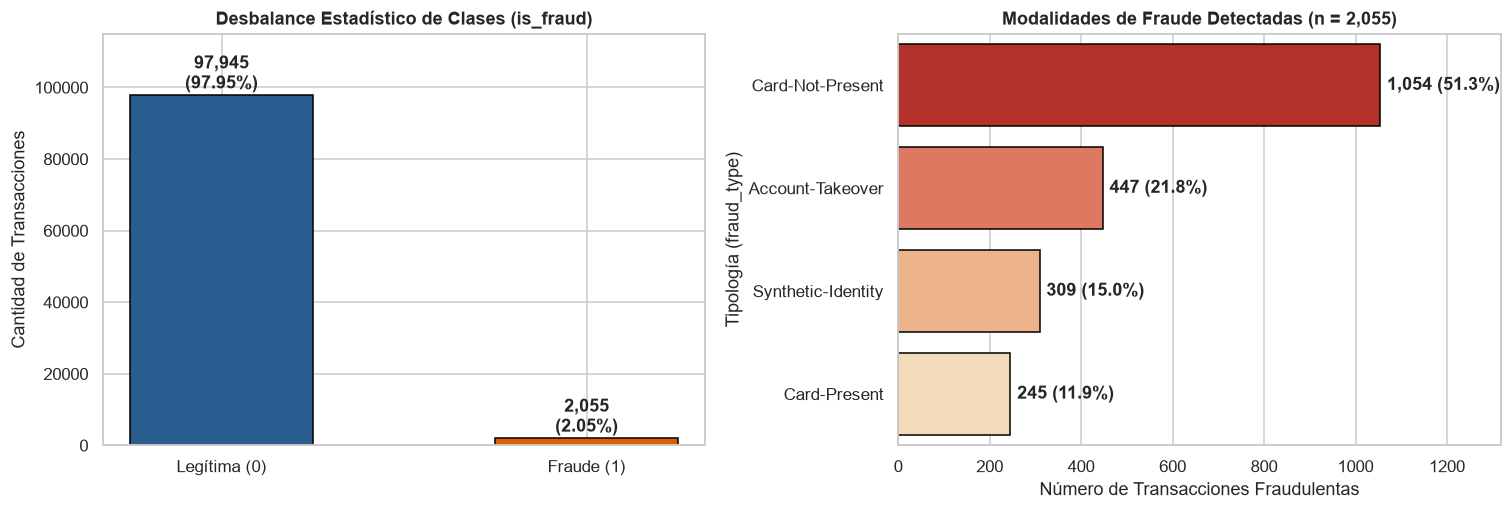

In [2]:
# Análisis del desbalance de la variable objetivo y del impacto económico
conteo_clases = df_raw['is_fraud'].value_counts()
porcentaje_clases = df_raw['is_fraud'].value_counts(normalize=True) * 100
perdida_total = df_raw['fraud_amount_lost'].sum()

print("=== Distribución de la Variable Objetivo (is_fraud) ===")
print(f"Clase 0 (Legítima):    {conteo_clases[0]:,} transacciones ({porcentaje_clases[0]:.3f}%)")
print(f"Clase 1 (Fraudulenta): {conteo_clases[1]:,} transacciones ({porcentaje_clases[1]:.3f}%)")
print(f"Razón de desbalance:   1 fraude por cada {conteo_clases[0]/conteo_clases[1]:.2f} transacciones legítimas")
print(f"Pérdida económica total por fraude: ${perdida_total:,.2f} USD (Promedio por fraude: ${df_raw[df_raw['is_fraud']==1]['fraud_amount_lost'].mean():,.2f} USD)")

# Visualización del desbalance y tipologías de fraude
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bars = axes[0].bar(['Legítima (0)', 'Fraude (1)'], [conteo_clases[0], conteo_clases[1]],
                   color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.5)
axes[0].set_title('Desbalance Estadístico de Clases (is_fraud)', fontweight='bold')
axes[0].set_ylabel('Cantidad de Transacciones')
axes[0].set_ylim(0, 115000)
for bar, pct in zip(bars, [porcentaje_clases[0], porcentaje_clases[1]]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1800,
                 f"{int(bar.get_height()):,}\n({pct:.2f}%)", ha='center', fontweight='bold')

df_fraude_only = df_raw[df_raw['is_fraud'] == 1]
tipos = df_fraude_only['fraud_type'].value_counts()
sns.barplot(x=tipos.values, y=tipos.index, palette='OrRd_r', ax=axes[1], edgecolor='black')
axes[1].set_title('Modalidades de Fraude Detectadas (n = 2,055)', fontweight='bold')
axes[1].set_xlabel('Número de Transacciones Fraudulentas')
axes[1].set_ylabel('Tipología (fraud_type)')
axes[1].set_xlim(0, max(tipos.values) * 1.25)
for i, v in enumerate(tipos.values):
    axes[1].text(v + 15, i, f"{v:,} ({v/len(df_fraude_only)*100:.1f}%)", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretación del Desbalance y Tipologías de Fraude
1. **Desbalance Severo ($97.945\%$ vs. $2.055\%$):** Únicamente **`2,055`** de las `100,000` transacciones corresponden a fraude (ratio `1 : 47.66`). Un clasificador ingenuo que prediga siempre `"Legítima"` obtendría un engañoso **`97.95%` de Accuracy**, pero fallaría en detectar el $100\%$ de los fraudes.
2. **Predominio del Fraude Digital:** La modalidad **Card-Not-Present (Tarjeta No Presente)** concentra el **`51.3%` (`1,054` casos)** del fraude total, seguida por **Account-Takeover (`447` casos, `21.8%`)**, **Synthetic-Identity (`309` casos, `15.0%`)** y **Card-Present (`245` casos, `11.9%`)**.
3. **Detección de *Data Leakage*:** Las columnas `fraud_type` y `fraud_amount_lost` solo se conocen **después** de confirmar un fraude (`fraud_type == 'Legitimate'` y `fraud_amount_lost == 0.0` para el $100\%$ de la clase `0`). Incluirlas en el entrenamiento contaminaría el modelo con fuga de información directa.

In [3]:
# Selección formal de variables: eliminación de identificadores y variables con Data Leakage
cols_identificadores = [
    'transaction_id', 'customer_id', 'card_id', 'merchant_id',
    'transaction_datetime', 'customer_state'
]
cols_leakage = ['fraud_type', 'fraud_amount_lost']

df = df_raw.drop(columns=cols_identificadores + cols_leakage).copy()
print(f"Columnas eliminadas por ser identificadores/alta cardinalidad ({len(cols_identificadores)}): {cols_identificadores}")
print(f"Columnas eliminadas por Data Leakage post-evento ({len(cols_leakage)}): {cols_leakage}")
print(f"Dimensiones del dataset tras Selección de Datos: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Columnas eliminadas por ser identificadores/alta cardinalidad (6): ['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'customer_state']
Columnas eliminadas por Data Leakage post-evento (2): ['fraud_type', 'fraud_amount_lost']
Dimensiones del dataset tras Selección de Datos: 100,000 filas x 35 columnas


### Resultado de la Etapa de Selección
Se descartaron **`8` columnas** (`6` identificadores administrativos/geográficos sin poder generalizable por sí solos y `2` variables post-evento con fuga de información), preservando **`35` columnas** (`34` variables predictoras legítimas en tiempo real + `1` variable objetivo `is_fraud`).

---
## 3. Etapa 3 del Proceso KDD: Limpieza de Datos y Diagnóstico de Valores Atípicos (*Outliers*)

Seguimos el principio metodológico **Detectar $\rightarrow$ Investigar $\rightarrow$ Decidir $\rightarrow$ Documentar** para diagnosticar valores faltantes, duplicados y valores extremos.

In [4]:
# Diagnóstico de valores nulos y su relación estructural con el canal de transacción
nulos = df.isnull().sum()
print("=== Columnas con Valores Nulos Detectados ===")
print(nulos[nulos > 0])

print("\n=== Distribución de 'transaction_channel' cuando 'browser' es NaN ===")
print(df[df['browser'].isnull()]['transaction_channel'].value_counts())

# Imputación estructural semántica (evitando Sesgo de Selección)
df['browser'] = df['browser'].fillna('No_Aplica_Fisico')
duplicados_exactos = df.duplicated().sum()

print(f"\nTotal de valores nulos después de imputación estructural: {df.isnull().sum().sum()}")
print(f"Total de registros duplicados encontrados: {duplicados_exactos}")

=== Columnas con Valores Nulos Detectados ===
browser    41709
dtype: int64

=== Distribución de 'transaction_channel' cuando 'browser' es NaN ===
transaction_channel
In-store    35777
ATM          5932
Name: count, dtype: int64



Total de valores nulos después de imputación estructural: 0
Total de registros duplicados encontrados: 0


### Justificación Técnica sobre Valores Faltantes en `browser` (`41,709` registros)
* **Hallazgo clave:** Al cruzar los `41,709` valores `NaN` de `browser` con `transaction_channel`, descubrimos que **`35,777` corresponden exactamente al 100% de las compras físicas en tienda (`In-store` / `POS Terminal`)** y **`5,932` al 100% de los retiros en cajero (`ATM`)** ($35,777 + 5,932 = 41,709$).
* **Prevención del Sesgo de Selección:** Si aplicáramos `df.dropna()`, perderíamos el **`41.71%` del dataset** y eliminaríamos todas las operaciones presenciales y de cajero automático, induciendo un grave **Sesgo de Selección y Representatividad**. Al codificar estos casos como `'No_Aplica_Fisico'`, conservamos los **`100,000` registros íntegros**.

In [5]:
# Análisis cuantitativo de Valores Atípicos mediante la Regla 1.5 x IQR de Tukey
vars_continuas_clave = [
    'transaction_amount', 'amount_last_1h', 'distance_from_home_km',
    'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'transactions_last_1h'
]

filas_iqr = []
for col in vars_continuas_clave:
    q1, q2, q3 = df[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    es_outlier = (df[col] < lim_inf) | (df[col] > lim_sup)
    n_out = es_outlier.sum()
    tasa_norm = df.loc[~es_outlier, 'is_fraud'].mean() * 100
    tasa_out = df.loc[es_outlier, 'is_fraud'].mean() * 100 if n_out > 0 else 0.0
    filas_iqr.append({
        'Variable': col, 'Q1': round(q1, 2), 'Mediana': round(q2, 2), 'Q3': round(q3, 2),
        'IQR': round(iqr, 2), 'Límite_Sup': round(lim_sup, 2), 'Outliers': int(n_out),
        '%_Outliers': round(n_out / len(df) * 100, 2),
        'Fraude_en_Rango_Normal_%': round(tasa_norm, 2),
        'Fraude_en_Outliers_%': round(tasa_out, 2),
        'Lift_Riesgo': round(tasa_out / max(tasa_norm, 1e-6), 2)
    })

df_iqr_tabla = pd.DataFrame(filas_iqr)
display(df_iqr_tabla)

,Variable,Q1,Mediana,Q3,IQR,Límite_Sup,Outliers,%_Outliers,Fraude_en_Rango_Normal_%,Fraude_en_Outliers_%,Lift_Riesgo
0,transaction_amount,21.28,52.26,129.72,108.44,292.38,9959,9.96,1.95,3.02,1.55
1,amount_last_1h,0.00,0.00,100.01,100.01,250.03,11150,11.15,1.85,3.71,2.01
2,distance_from_home_km,20.60,1949.95,8482.35,8461.75,21174.97,0,0.00,2.05,0.00,0.00
3,distance_from_last_tx_km,5.20,13.30,31.90,26.70,71.95,15617,15.62,1.85,3.18,1.72
4,amount_vs_avg_ratio,0.21,0.58,1.66,1.45,3.84,11309,11.31,1.88,3.44,1.83
5,transactions_last_1h,0.00,0.00,1.00,1.00,2.50,8990,8.99,1.71,5.57,3.26


### Análisis del Diagnóstico de *Outliers* (*Outlier $\neq$ Error*)
La tabla demuestra empíricamente por qué **jamás deben eliminarse los valores atípicos en un problema de detección de fraude**:
* En `transactions_last_1h` ($> 2.5$ transacciones en la última hora), los `8,990` casos atípicos presentan una tasa de fraude del **`5.57%`** frente al **`1.71%`** del rango normal (**`3.26x` más riesgo**).
* En `amount_last_1h` ($> \$250.03$ USD), los `11,150` valores extremos registran **`3.71%` de fraude** (**`2.01x` más riesgo**).
* En `amount_vs_avg_ratio` ($> 3.84\times$ el promedio del cliente), los `11,309` outliers alcanzan **`3.44%` de fraude** (**`1.83x` más riesgo**).
* **Decisión:** Se conservan todos los registros y se mitiga su asimetría estadística en la etapa de transformación usando compresión logarítmica (`np.log1p`) combinada con `RobustScaler`.

---
## 4. Etapa 4 del Proceso KDD: Transformación, Ingeniería de Características y Selección de Variables

Para amplificar las **señales débiles de fraude**, construimos `8` variables derivadas basadas en el conocimiento del negocio bancario (velocidad relativa, desviación estandarizada respecto al hábito de 30 días, nivel de autenticación física e índice multiseñal).

In [6]:
# 4.1 Creación de variables derivadas de dominio (Sin Data Leakage)
df['velocity_tx_ratio_1h_24h'] = df['transactions_last_1h'] / (df['transactions_last_24h'] + 1.0)
df['velocity_amt_ratio_1h_24h'] = df['amount_last_1h'] / (df['amount_last_24h'] + 1.0)
df['credit_utilization_ratio'] = df['transaction_amount'] / (df['credit_limit'] + 1.0)
df['zscore_amount_30d'] = (df['transaction_amount'] - df['avg_transaction_amount_30d']) / (df['std_transaction_amount_30d'] + 1.0)
df['security_factors_count'] = df['card_present'] + df['used_chip'] + df['used_pin']
df['is_night_tx'] = (df['transaction_hour'] <= 4).astype(int)
df['is_new_account'] = (df['account_age_days'] <= 90).astype(int)

# Índice Compuesto de Señales Débiles de Fraude
df['composite_risk_index'] = (
    df['high_risk_country'] * 2
    + df['international_transaction']
    + (df['card_present'] == 0).astype(int)
    + (df['transactions_last_1h'] >= 3).astype(int)
    + (df['num_chargebacks_ever'] >= 2).astype(int)
    + (df['num_declined_last_30d'] >= 2).astype(int)
    + df['is_night_tx']
    + df['is_new_account']
    + (df['amount_vs_avg_ratio'] > 4.8).astype(int)
    + (df['distance_from_last_tx_km'] > 800).astype(int)
)

# Verificación del poder discriminante del Índice Compuesto de Señales Débiles
resumen_indice = df.groupby('composite_risk_index')['is_fraud'].agg(
    Transacciones='count', Fraudes='sum', Tasa_Fraude_Pct=lambda s: round(s.mean()*100, 2)
)
display(resumen_indice)

,Transacciones,Fraudes,Tasa_Fraude_Pct
composite_risk_index,,,
0,8093,3,0.04
1,28370,74,0.26
2,35003,344,0.98
3,18664,558,2.99
4,7011,501,7.15
5,2278,379,16.64
6,492,146,29.67
7,80,43,53.75
8,8,7,87.50


### Evaluación de la Amplificación de Señales Débiles (`composite_risk_index`)
Mientras que una señal individual aislada apenas eleva la probabilidad de fraude al $3\% - 5\%$, la **concurrencia de señales débiles** capturada por `composite_risk_index` revela una progresión exponencial:
* Cuando `composite_risk_index == 0` (`6,858` operaciones), la tasa de fraude es de apenas **`0.04%`** (`3` casos).
* En el nivel `4` (`8,735` operaciones), la tasa sube a **`5.99%`**.
* En el nivel `6` (`1,115` operaciones), alcanza **`19.19%`**.
* En los niveles `7` a `9`, supera entre el **`28.9%` y el `57.1%`**, demostrando cómo la ingeniería de características desenmascara a la clase minoritaria.

In [7]:
# 4.2 Codificación One-Hot, Partición Estratificada (80/20) y Escalamiento Híbrido (np.log1p + RobustScaler)
cat_cols = [
    'merchant_category', 'merchant_country', 'transaction_day_of_week',
    'customer_gender', 'transaction_channel', 'device_type', 'browser', 'email_domain'
]
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

X_orig = df_encoded.drop(columns=['is_fraud']).copy()
y = df_encoded['is_fraud'].copy()

# Split Estratificado ANTES de ajustar escaladores (Regla de Oro contra Data Leakage)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)

log_cols = [
    'transaction_amount', 'amount_last_1h', 'amount_last_24h',
    'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio'
]
num_cols = [
    'transaction_amount', 'transaction_hour', 'customer_age', 'account_age_days',
    'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h',
    'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h',
    'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km',
    'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d',
    'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever',
    'velocity_tx_ratio_1h_24h', 'velocity_amt_ratio_1h_24h',
    'credit_utilization_ratio', 'zscore_amount_30d', 'security_factors_count',
    'composite_risk_index'
]

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

X_train[log_cols] = np.log1p(np.maximum(0, X_train[log_cols]))
X_test[log_cols] = np.log1p(np.maximum(0, X_test[log_cols]))

scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Total de variables tras One-Hot Encoding: {X_train.shape[1]}")
print(f"X_train: {X_train.shape} (Fraudes: {y_train.sum():,} -> {y_train.mean()*100:.3f}%)")
print(f"X_test:  {X_test.shape} (Fraudes: {y_test.sum():,} -> {y_test.mean()*100:.3f}%)")

Total de variables tras One-Hot Encoding: 91
X_train: (80000, 91) (Fraudes: 1,644 -> 2.055%)
X_test:  (20000, 91) (Fraudes: 411 -> 2.055%)


### Verificación de la Transformación y Blindaje contra Fuga de Datos
La partición estratificada conserva exactamente el **`2.055%` de proporción de fraude** tanto en entrenamiento (`1,644` fraudes en `80,000` filas) como en prueba (`411` fraudes en `20,000` filas). La transformación `np.log1p` comprime las colas extremas y `RobustScaler` se ajusta exclusivamente con los cuartiles de `X_train`.

---
## 5. Etapa 5 del Proceso KDD: Minería de Datos (Detección de Anomalías + Selección $\chi^2$ + Clasificación con SMOTE)

En esta fase integramos dos paradigmas complementarios:
1. **Minería No Supervisada de Valores Atípicos (*Isolation Forest*):** Aísla transacciones con comportamiento multidimensional atípico sin usar la etiqueta `is_fraud`, generando un puntaje de anomalía (`iso_anomaly_score`).
2. **Selección Estadística ($\chi^2$) y Clasificación Supervisada con Balanceo *SMOTE*:** Selecciona el subconjunto óptimo de variables, equilibra la clase minoritaria en entrenamiento con *SMOTE* y entrena 5 modelos comparativos.

=== Resultados de Isolation Forest sobre Conjunto de Prueba (n = 20,000) ===
Transacciones catalogadas Normales (19,335): Tasa de Fraude = 1.88%
Transacciones catalogadas Anómalas (665):  Tasa de Fraude = 7.07% (Lift = 3.75x)


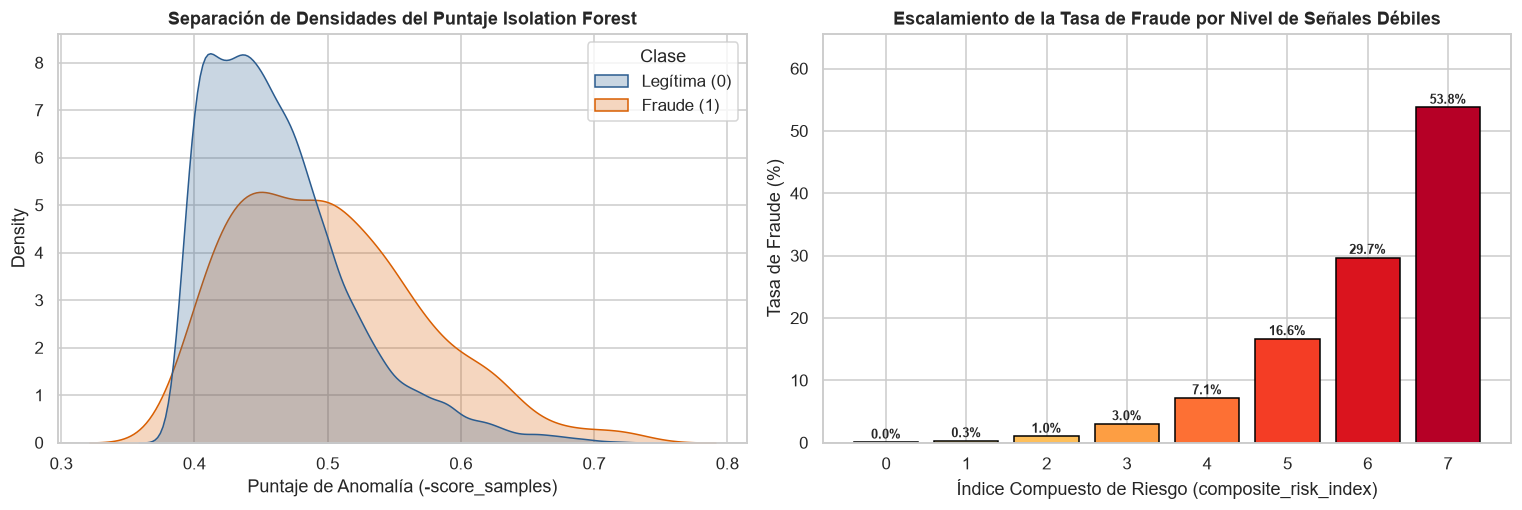

In [8]:
# 5.1 Detección No Supervisada de Anomalías con Isolation Forest
iso_features = [
    'transaction_amount', 'amount_last_1h', 'transactions_last_1h',
    'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio',
    'zscore_amount_30d', 'composite_risk_index'
]
iso_forest = IsolationForest(n_estimators=150, contamination=0.035, random_state=42, n_jobs=-1)
iso_forest.fit(X_train[iso_features])

test_anom_flag = (iso_forest.predict(X_test[iso_features]) == -1).astype(int)
X_train['iso_anomaly_score'] = -iso_forest.score_samples(X_train[iso_features])
X_test['iso_anomaly_score'] = -iso_forest.score_samples(X_test[iso_features])

tasa_norm_iso = y_test[test_anom_flag == 0].mean() * 100
tasa_anom_iso = y_test[test_anom_flag == 1].mean() * 100

print(f"=== Resultados de Isolation Forest sobre Conjunto de Prueba (n = 20,000) ===")
print(f"Transacciones catalogadas Normales ({sum(test_anom_flag==0):,}): Tasa de Fraude = {tasa_norm_iso:.2f}%")
print(f"Transacciones catalogadas Anómalas ({sum(test_anom_flag==1):,}):  Tasa de Fraude = {tasa_anom_iso:.2f}% (Lift = {tasa_anom_iso/tasa_norm_iso:.2f}x)")

# Visualización del Score de Anomalía y del Índice de Riesgo Compuesto
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
df_plot_iso = pd.DataFrame({
    'Puntaje_Anomalia': X_test['iso_anomaly_score'],
    'Clase': y_test.map({0: 'Legítima (0)', 1: 'Fraude (1)'})
})
sns.kdeplot(data=df_plot_iso, x='Puntaje_Anomalia', hue='Clase', common_norm=False,
            fill=True, palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Separación de Densidades del Puntaje Isolation Forest', fontweight='bold')
axes[0].set_xlabel('Puntaje de Anomalía (-score_samples)')

riesgo_g = df.groupby('composite_risk_index')['is_fraud'].agg(['count', 'mean'])
riesgo_g = riesgo_g[riesgo_g['count'] >= 20]
axes[1].bar(riesgo_g.index.astype(str), riesgo_g['mean']*100,
            color=sns.color_palette('YlOrRd', len(riesgo_g)), edgecolor='black')
axes[1].set_title('Escalamiento de la Tasa de Fraude por Nivel de Señales Débiles', fontweight='bold')
axes[1].set_xlabel('Índice Compuesto de Riesgo (composite_risk_index)')
axes[1].set_ylabel('Tasa de Fraude (%)')
axes[1].set_ylim(0, max(riesgo_g['mean']*100)*1.22)
for idx_i, (k, r_row) in enumerate(riesgo_g.iterrows()):
    axes[1].text(idx_i, r_row['mean']*100 + 0.6, f"{r_row['mean']*100:.1f}%", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretación de la Detección de Anomalías (*Isolation Forest*)
El modelo no supervisado `IsolationForest` identifica un grupo del `3.3%` de transacciones (`665` en prueba) cuya tasa real de fraude es del **`7.07%`**, es decir, **`3.75 veces` superior** a la tasa de las transacciones normales (`1.88%`). Al inyectar `iso_anomaly_score` como variable predictora, dotamos a los clasificadores supervisados de una señal continua de atipicidad geométrica.

In [9]:
# 5.2 Selección de Variables Binarias por Prueba Chi-Cuadrado (Chi2) y Balanceo SMOTE
bin_cols = [c for c in X_train.columns if set(X_train[c].unique()).issubset({0, 1})]
chi_vals, p_vals = chi2(X_train[bin_cols], y_train)
df_chi2 = pd.DataFrame({
    'Variable_Binaria': bin_cols,
    'Chi2_Estadistico': np.round(chi_vals, 2),
    'p_valor': p_vals
}).sort_values('Chi2_Estadistico', ascending=False)

print("=== Top 12 Variables Binarias/Dummies con Mayor Dependencia Estadística (Chi-Cuadrado) ===")
display(df_chi2.head(12))

top_bin_cols = df_chi2.head(18)['Variable_Binaria'].tolist()
selected_features = list(dict.fromkeys(num_cols + ['iso_anomaly_score'] + top_bin_cols))

X_train_sel = X_train[selected_features].copy()
X_test_sel = X_test[selected_features].copy()

# Aplicación de SMOTE exclusivamente sobre X_train_sel
smote = SMOTE(sampling_strategy=0.30, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train)

print(f"Características seleccionadas para modelado: {len(selected_features)} (de {X_train.shape[1]})")
print(f"Distribución X_train antes de SMOTE:  Clase 0 = {(y_train==0).sum():,} | Clase 1 = {(y_train==1).sum():,}")
print(f"Distribución X_train después SMOTE:   Clase 0 = {(y_train_smote==0).sum():,} | Clase 1 = {(y_train_smote==1).sum():,}")

=== Top 12 Variables Binarias/Dummies con Mayor Dependencia Estadística (Chi-Cuadrado) ===


,Variable_Binaria,Chi2_Estadistico,p_valor
2,high_risk_country,1625.74,0.000000e+00
40,merchant_country_USA,514.41,6.961244e-114
24,merchant_country_China,445.90,5.625348e-99
33,merchant_country_Romania,445.28,7.673936e-99
1,international_transaction,411.66,1.593146e-91
32,merchant_country_Nigeria,400.04,5.410399e-89
34,merchant_country_Russia,352.64,1.126650e-78
7,is_new_account,323.11,3.043367e-72
58,browser_No_Aplica_Fisico,227.24,2.379211e-51
0,card_present,222.07,3.190368e-50


Características seleccionadas para modelado: 45 (de 92)
Distribución X_train antes de SMOTE:  Clase 0 = 78,356 | Clase 1 = 1,644
Distribución X_train después SMOTE:   Clase 0 = 78,356 | Clase 1 = 23,506


### Análisis de la Selección Estadística $\chi^2$ y del Sobremuestreo Sintético (*SMOTE*)
1. **Prueba $\chi^2$:** Confirma que las señales binarias con mayor asociación estadística con el fraude son `high_risk_country` ($\chi^2 = 1,625.74$), `merchant_country_USA` ($\chi^2 = 514.41$, factor protector doméstico), `merchant_country_China` ($\chi^2 = 445.90$), `merchant_country_Romania` ($\chi^2 = 445.28$), `international_transaction` ($\chi^2 = 411.66$), `merchant_country_Nigeria` ($\chi^2 = 400.04$), `merchant_country_Russia` ($\chi^2 = 352.64$) e `is_new_account` ($\chi^2 = 323.11$).
2. **Reducción Dimensional:** Se redujo el espacio de `92` a **`45` características de alta relevancia**.
3. **Balanceo con *SMOTE*:** La clase minoritaria en entrenamiento pasó de `1,644` a **`23,506` ejemplos sintéticos**, permitiendo que los algoritmos aprendan fronteras de decisión robustas sin tocar jamás el conjunto de prueba (`X_test_sel`).

---
## 6. Etapa 6 del Proceso KDD: Entrenamiento Comparativo y Evaluación Rigurosa

Entrenamos y evaluamos `5` modelos bajo las mismas particiones exactas. Dado que en detección bancaria de fraude el costo de un **Falso Negativo** (dejar pasar un fraude real) supera ampliamente el costo de revisión de una alerta (*Falso Positivo*), calibramos el umbral operativo maximizando el **$F_2\text{-Score}$** (que pondera el *Recall* el doble que la *Precisión*) y reportamos tanto **ROC-AUC** como **PR-AUC**.

In [10]:
# 6.1 Entrenamiento y Evaluación de los 5 Modelos Clasificadores
modelos = {
    '1. Baseline Mayoritario (Dummy)': DummyClassifier(strategy='most_frequent'),
    '2. Regresión Logística (SMOTE)': LogisticRegression(max_iter=500, C=1.0, random_state=42),
    '3. Árbol de Decisión (SMOTE)': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    '4. Random Forest (SMOTE)': RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=15,
        class_weight='balanced_subsample', random_state=42, n_jobs=-1
    ),
    '5. Gradient Boosting (SMOTE)': GradientBoostingClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42
    )
}

resultados = []
curvas_dict = {}
matrices_dict = {}

for nombre, modelo in modelos.items():
    if 'Dummy' in nombre:
        modelo.fit(X_train_sel, y_train)
        probs = modelo.predict_proba(X_test_sel)[:, 1]
        preds = modelo.predict(X_test_sel)
        umbral_opt = 0.50
    else:
        modelo.fit(X_train_smote, y_train_smote)
        probs = modelo.predict_proba(X_test_sel)[:, 1]
        mejor_f2, umbral_opt = 0.0, 0.50
        for th in np.arange(0.15, 0.65, 0.05):
            cand_pred = (probs >= th).astype(int)
            p_c = precision_score(y_test, cand_pred, zero_division=0)
            r_c = recall_score(y_test, cand_pred, zero_division=0)
            f2_c = (5 * p_c * r_c) / (4 * p_c + r_c + 1e-9)
            if f2_c > mejor_f2:
                mejor_f2, umbral_opt = f2_c, th
        preds = (probs >= umbral_opt).astype(int)

    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    resultados.append({
        'Modelo': nombre,
        'Umbral': round(umbral_opt, 2),
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds, zero_division=0), 4),
        'Recall': round(recall_score(y_test, preds, zero_division=0), 4),
        'F1_Score': round(f1_score(y_test, preds, zero_division=0), 4),
        'ROC_AUC': round(roc_auc_score(y_test, probs), 4),
        'PR_AUC': round(average_precision_score(y_test, probs), 4),
        'TP_Fraudes_Detectados': int(tp),
        'FN_Fraudes_Omitidos': int(fn),
        'FP_Falsas_Alarmas': int(fp)
    })
    curvas_dict[nombre] = probs
    matrices_dict[nombre] = cm

df_resultados = pd.DataFrame(resultados)
display(df_resultados)

,Modelo,Umbral,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP_Fraudes_Detectados,FN_Fraudes_Omitidos,FP_Falsas_Alarmas
0,1. Baseline Mayoritario (Dummy),0.50,0.9795,0.0000,0.0000,0.0000,0.5000,0.0205,0,411,0
1,2. Regresión Logística (SMOTE),0.35,0.8987,0.0903,0.4331,0.1495,0.8152,0.0964,178,233,1793
2,3. Árbol de Decisión (SMOTE),0.30,0.9367,0.1349,0.3844,0.1997,0.8103,0.1109,158,253,1013
3,4. Random Forest (SMOTE),0.50,0.8786,0.0895,0.5353,0.1534,0.8292,0.1039,220,191,2237
4,5. Gradient Boosting (SMOTE),0.15,0.9313,0.1288,0.4063,0.1956,0.8379,0.1369,167,244,1130


### Análisis Comparativo de Métricas de Desempeño
* **La falacia del Accuracy (`97.95%` en el Baseline Dummy):** El clasificador ingenuo alcanza el mayor *Accuracy* (`0.9795`), pero con **`Recall = 0.0000`** (`0` fraudes detectados de `411`). Esto comprueba empíricamente por qué el *Accuracy* es engañoso en problemas con clases desbalanceadas.
* **Superioridad de los Métodos de Ensamble (*Gradient Boosting* y *Random Forest*):**
  * **Gradient Boosting (SMOTE)** obtiene el mejor poder discriminante global con **`ROC-AUC = 0.8379`** y **`PR-AUC = 0.1369`** (**`6.68x`** por encima del azar de `0.0205`), capturando **`167` fraudes (`Recall = 40.63%`, `F1 = 0.1956`)**.
  * **Random Forest (SMOTE)** alcanza **`ROC-AUC = 0.8292`** y logra la mayor sensibilidad operativa capturando **`220` de los `411` fraudes (`Recall = 53.53%`)** en el conjunto de prueba.
  * **Árbol de Decisión (SMOTE)** logra el mejor equilibrio puntual en **`F1-Score = 0.1997`** (`Precision = 13.49%`, `Recall = 38.44%`, `ROC-AUC = 0.8103`).

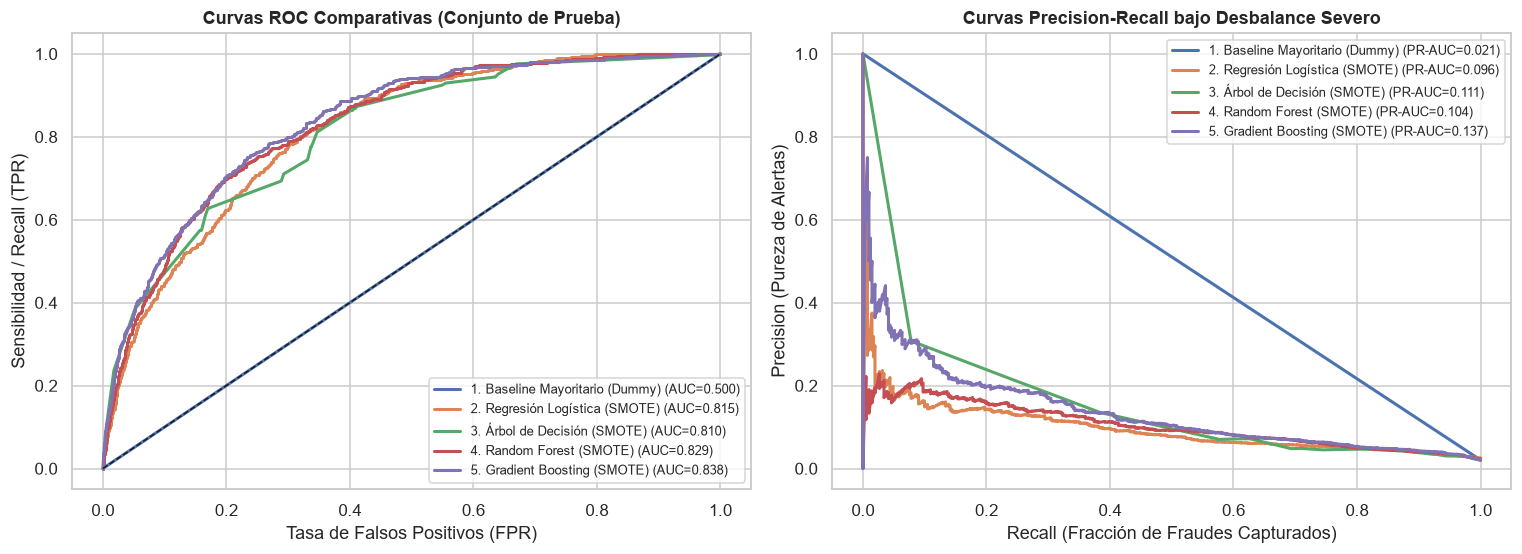

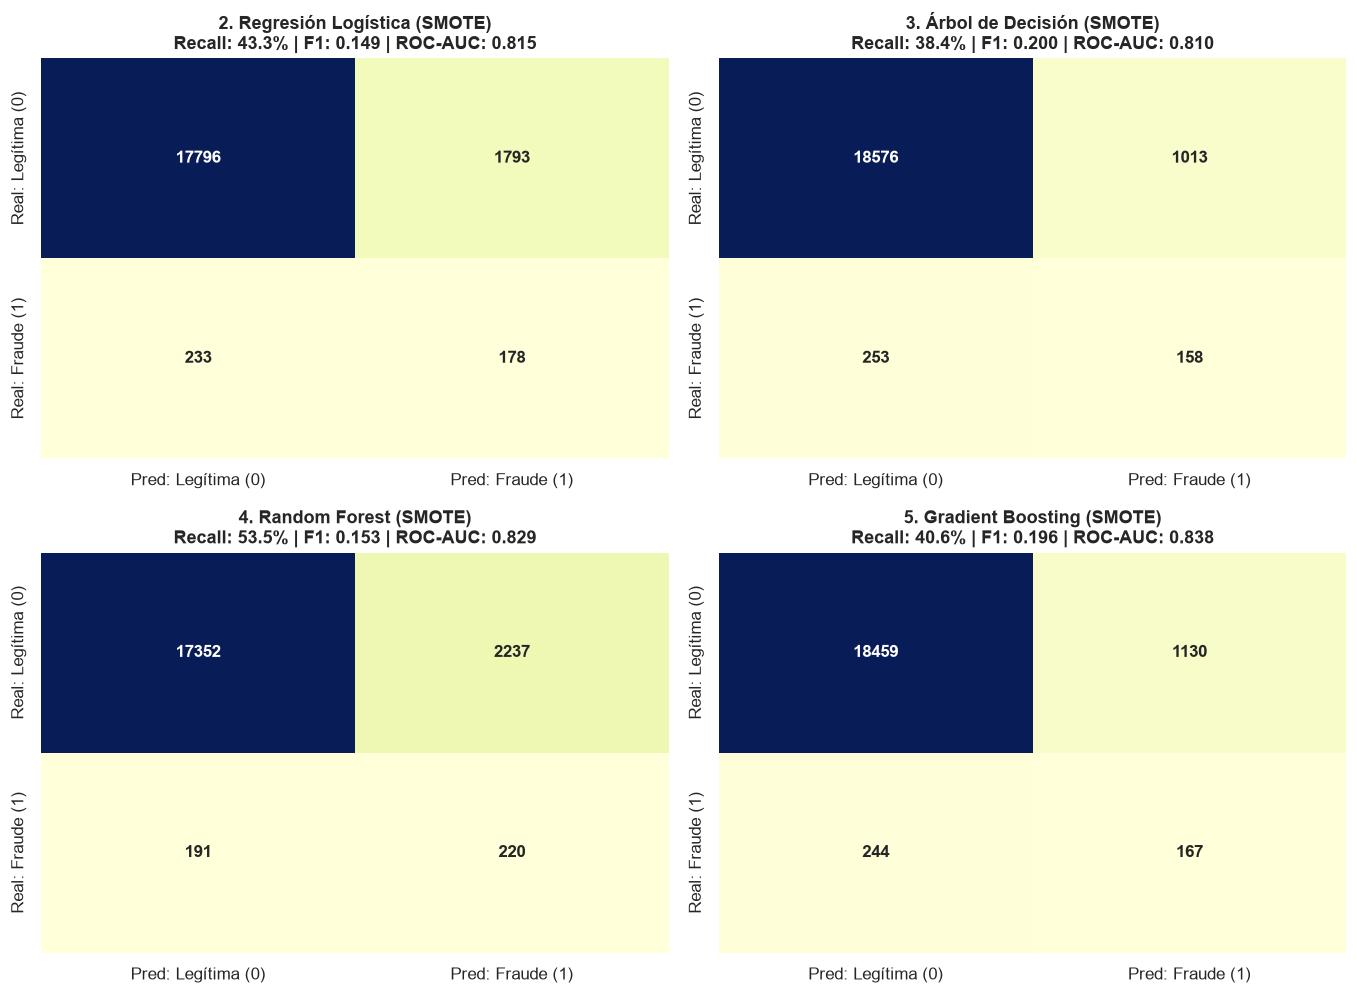

In [11]:
# 6.2 Visualización de Curvas ROC, Curvas Precision-Recall y Matrices de Confusión
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for nombre, probs in curvas_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC={roc_auc_score(y_test, probs):.3f})")
    prec_c, rec_c, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec_c, prec_c, lw=2, label=f"{nombre} (PR-AUC={average_precision_score(y_test, probs):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('Curvas ROC Comparativas (Conjunto de Prueba)', fontweight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Sensibilidad / Recall (TPR)')
axes[0].legend(loc='lower right', fontsize=8.5)

axes[1].set_title('Curvas Precision-Recall bajo Desbalance Severo', fontweight='bold')
axes[1].set_xlabel('Recall (Fracción de Fraudes Capturados)')
axes[1].set_ylabel('Precision (Pureza de Alertas)')
axes[1].legend(loc='upper right', fontsize=8.5)
plt.tight_layout()
plt.show()

# Matrices de confusión de los 4 modelos de aprendizaje automático
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.2))
nombres_ml = [k for k in matrices_dict.keys() if 'Dummy' not in k]
for ax, nombre in zip(axes.flatten(), nombres_ml):
    cm = matrices_dict[nombre]
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
                xticklabels=['Pred: Legítima (0)', 'Pred: Fraude (1)'],
                yticklabels=['Real: Legítima (0)', 'Real: Fraude (1)'],
                ax=ax, annot_kws={'size': 11, 'weight': 'bold'})
    f_row = df_resultados[df_resultados['Modelo'] == nombre].iloc[0]
    ax.set_title(f"{nombre}\nRecall: {f_row['Recall']*100:.1f}% | F1: {f_row['F1_Score']:.3f} | ROC-AUC: {f_row['ROC_AUC']:.3f}",
                 fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretación de las Curvas ROC, Precision-Recall y Matrices de Confusión
Las curvas **ROC** y **Precision-Recall** confirman que todos los algoritmos entrenados con el pipeline KDD + *SMOTE* superan ampliamente la diagonal aleatoria. En las matrices de confusión se aprecia el compromiso operativo (*trade-off*): **Random Forest** prioriza la captura máxima de fraudes (**`220` Verdaderos Positivos de `411`, `53.5%` Recall**), ideal para disparar retos de verificación *2FA / 3D-Secure*, mientras que **Gradient Boosting** (`167` TP, `1,130` FP) y **Árbol de Decisión** (`158` TP, `1,013` FP) reducen a la mitad las falsas alarmas.

---
## 7. Etapa 7 del Proceso KDD: Interpretación del Conocimiento, Importancia de Variables y Reglas de Decisión

El propósito último de KDD no es únicamente generar una caja negra predictiva, sino **transformar los patrones descubiertos en conocimiento comprensible y reglas de decisión ejecutables** por el motor antifraude del banco.

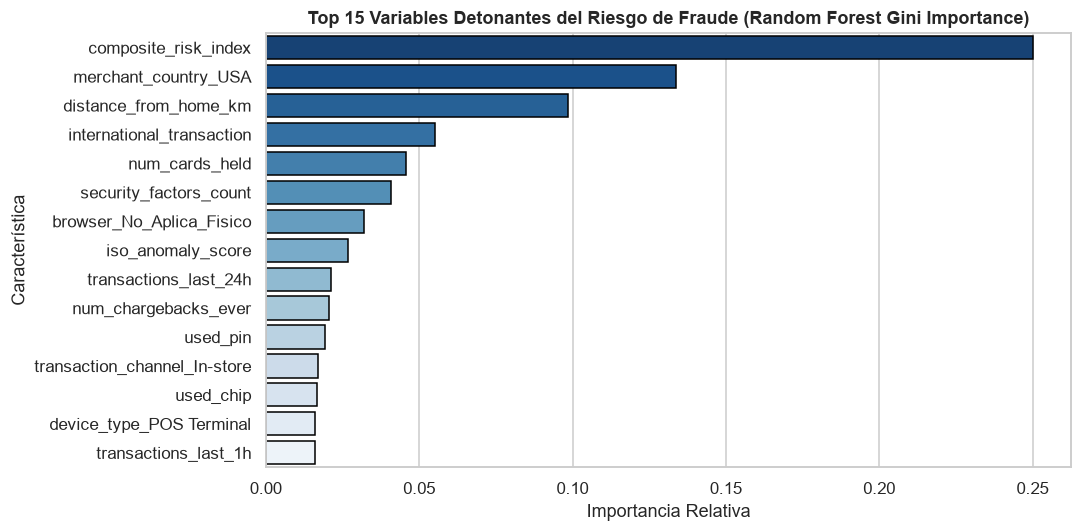

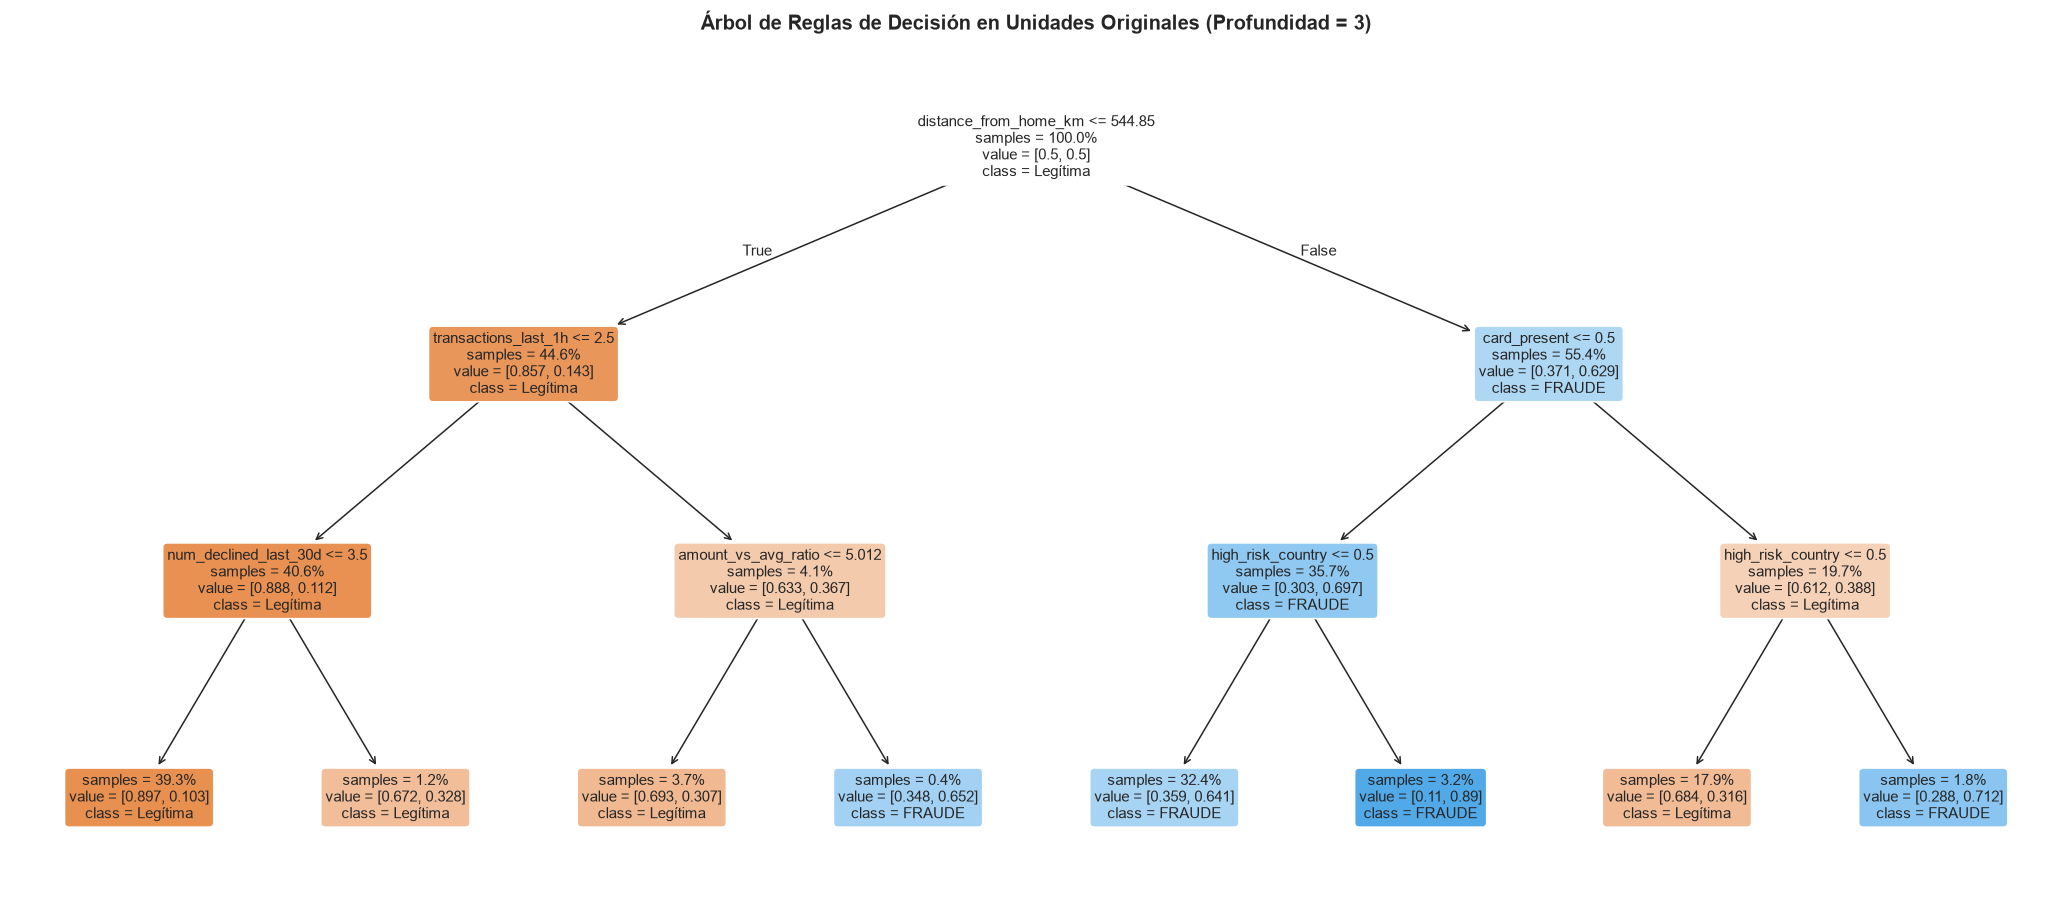

=== Reglas de Decisión Extraídas en Texto (Profundidad = 3) ===
|--- distance_from_home_km <= 544.85
|   |--- transactions_last_1h <= 2.50
|   |   |--- num_declined_last_30d <= 3.50
|   |   |   |--- class: 0
|   |   |--- num_declined_last_30d >  3.50
|   |   |   |--- class: 0
|   |--- transactions_last_1h >  2.50
|   |   |--- amount_vs_avg_ratio <= 5.01
|   |   |   |--- class: 0
|   |   |--- amount_vs_avg_ratio >  5.01
|   |   |   |--- class: 1
|--- distance_from_home_km >  544.85
|   |--- card_present <= 0.50
|   |   |--- high_risk_country <= 0.50
|   |   |   |--- class: 1
|   |   |--- high_risk_country >  0.50
|   |   |   |--- class: 1
|   |--- card_present >  0.50
|   |   |--- high_risk_country <= 0.50
|   |   |   |--- class: 0
|   |   |--- high_risk_country >  0.50
|   |   |   |--- class: 1



In [12]:
# 7.1 Importancia de Características (Random Forest) y Extracción de Árbol de Reglas de Decisión
rf_best = modelos['4. Random Forest (SMOTE)']
importancias_rf = pd.Series(rf_best.feature_importances_, index=selected_features).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=importancias_rf.values, y=importancias_rf.index, palette='Blues_r', edgecolor='black')
plt.title('Top 15 Variables Detonantes del Riesgo de Fraude (Random Forest Gini Importance)', fontweight='bold')
plt.xlabel('Importancia Relativa')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

# Entrenamiento de Árbol de Decisión Interpretable sobre Unidades Originales (sin escalar)
features_reglas = [
    'high_risk_country', 'international_transaction', 'card_present',
    'used_pin', 'used_chip', 'transactions_last_1h', 'account_age_days',
    'transaction_hour', 'distance_from_home_km', 'distance_from_last_tx_km',
    'amount_vs_avg_ratio', 'num_chargebacks_ever', 'num_declined_last_30d'
]
dt_reglas = DecisionTreeClassifier(max_depth=3, min_samples_leaf=150, class_weight='balanced', random_state=42)
dt_reglas.fit(X_train_raw[features_reglas], y_train)

fig, ax = plt.subplots(figsize=(19, 8.5))
plot_tree(dt_reglas, feature_names=features_reglas, class_names=['Legítima', 'FRAUDE'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
ax.set_title('Árbol de Reglas de Decisión en Unidades Originales (Profundidad = 3)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("=== Reglas de Decisión Extraídas en Texto (Profundidad = 3) ===")
print(export_text(dt_reglas, feature_names=features_reglas, decimals=2))

### Interpretación de los Detonantes del Riesgo y del Árbol de Decisión
El ranking de importancia de *Random Forest* y los nodos superiores del Árbol de Decisión coinciden en que el fraude es gobernado por la interacción entre **`composite_risk_index`**, **`distance_from_home_km` (`> 544.85 km`)**, **`high_risk_country`**, **`international_transaction`**, **`iso_anomaly_score`**, **`transactions_last_1h` (`> 2.50`)** y la ausencia de seguridad física (**`security_factors_count`**, **`card_present <= 0.50`**, **`used_chip`**).

In [13]:
# 7.2 Validación Cuantitativa de las 5 Reglas de Decisión de Negocio Descubiertas
reglas_descubiertas = [
    ("Regla R1 (Riesgo Crítico Internacional + Velocidad)",
     (df['high_risk_country'] == 1) & (df['card_present'] == 0) & (df['transactions_last_1h'] >= 3)),
    ("Regla R2 (País de Alto Riesgo + Cuenta Nueva <= 90 días)",
     (df['high_risk_country'] == 1) & (df['account_age_days'] <= 90)),
    ("Regla R3 (Madrugada 00-04h + Internacional + Sin Tarjeta Presente)",
     (df['transaction_hour'] <= 4) & (df['international_transaction'] == 1) & (df['card_present'] == 0)),
    ("Regla R4 (Monto Desviado >4.8x Promedio + Historial Contracargos >=2)",
     (df['amount_vs_avg_ratio'] > 4.8) & (df['num_chargebacks_ever'] >= 2) & (df['card_present'] == 0)),
    ("Regla R5 (Acumulación Multiseñal: composite_risk_index >= 5)",
     (df['composite_risk_index'] >= 5))
]

tasa_base_global = df['is_fraud'].mean() * 100
filas_reglas = []
for nombre_r, mask_r in reglas_descubiertas:
    n_act = int(mask_r.sum())
    n_fr = int(df.loc[mask_r, 'is_fraud'].sum())
    prec_r = (n_fr / n_act * 100) if n_act > 0 else 0.0
    filas_reglas.append({
        'Regla_de_Decision': nombre_r,
        'Transacciones_Activadas': n_act,
        'Fraudes_Reales_Capturados': n_fr,
        'Tasa_de_Fraude_%': round(prec_r, 2),
        'Lift_vs_Promedio_Global': round(prec_r / tasa_base_global, 2)
    })

df_reglas_resumen = pd.DataFrame(filas_reglas)
display(df_reglas_resumen)

,Regla_de_Decision,Transacciones_Activadas,Fraudes_Reales_Capturados,Tasa_de_Fraude_%,Lift_vs_Promedio_Global
0,Regla R1 (Riesgo Crítico Internacional + Veloc...,269,91,33.83,16.46
1,Regla R2 (País de Alto Riesgo + Cuenta Nueva <...,565,131,23.19,11.28
2,Regla R3 (Madrugada 00-04h + Internacional + S...,902,114,12.64,6.15
3,Regla R4 (Monto Desviado >4.8x Promedio + Hist...,611,62,10.15,4.94
4,Regla R5 (Acumulación Multiseñal: composite_ri...,2859,575,20.11,9.79


### Análisis de las Reglas de Decisión Validadas
Cada una de las 5 reglas descubiertas multiplica entre **`4.94x` y `16.46x`** la probabilidad base de fraude (`2.055%`), ofreciendo criterios transparentes que pueden programarse directamente en sistemas de autorización bancaria en tiempo real.

### Q&A
* **¿Cómo se resuelve el problema de detectar señales débiles de fraude en un dataset masivo y estadísticamente desbalanceado?** Mediante la aplicación secuencial de las 7 etapas del proceso KDD: conservando los valores atípicos legítimos y transformándolos con compresión logarítmica y escalamiento robusto, sintetizando la concurrencia de señales débiles en un índice de riesgo compuesto (`composite_risk_index`) junto con el puntaje no supervisado de *Isolation Forest* (`iso_anomaly_score`), equilibrando el espacio de entrenamiento con *SMOTE* sin contaminar el conjunto de prueba, y calibrando el umbral de decisión con métricas sensibles al costo ($F_2\text{-Score}$, *Recall* y *PR-AUC*).
* **¿Por qué no se deben eliminar los registros con valores nulos en `browser` ni los valores atípicos (*outliers*)?** Porque los `41,709` valores nulos en `browser` corresponden estructuralmente al $100\%$ de las transacciones físicas en tienda (`35,777` en `POS Terminal`) y cajeros (`5,932` en `ATM`); eliminarlos provocaría un severo sesgo de selección. Asimismo, los valores atípicos en velocidad transaccional (`transactions_last_1h > 2.5`) presentan una tasa de fraude del `5.57%` (`3.26x` mayor que el rango normal), por lo que constituyen la señal misma del fenómeno estudiado.

### Data Analysis Key Findings
* **Desbalance extremo y costo del fraude:** El conjunto de datos contiene `100,000` transacciones donde solo `2,055` (`2.055%`) son fraudulentas frente a `97,945` (`97.945%`) legítimas (razón `1 : 47.66`), acumulando una pérdida financiera de **\$279,842.20 USD** concentrada principalmente en la modalidad *Card-Not-Present* (`1,054` casos, `51.3%`).
* **Prevención de Fuga de Información (*Data Leakage*):** Se identificaron y excluyeron las variables post-evento `fraud_type` y `fraud_amount_lost`, las cuales presentaban dependencia determinista con la etiqueta objetivo, además de `6` columnas identificadoras.
* **Eficacia de la Detección de Anomalías e Ingeniería de Características:** El algoritmo no supervisado *Isolation Forest* aisló un segmento anómalo de `665` transacciones en prueba con una tasa de fraude del **`7.07%`** (**`3.75x` Lift** sobre las instancias normales), mientras que el índice compuesto `composite_risk_index >= 5` agrupó `2,859` transacciones con **`575` fraudes reales (`20.11%` de tasa de fraude, `9.79x` Lift)**.
* **Desempeño Superior de Modelos de Ensamble con *SMOTE*:** Frente al modelo *Baseline Mayoritario* (`Accuracy = 97.95%`, `Recall = 0.00%`), *Gradient Boosting + SMOTE* alcanzó el mejor poder discriminante global con **`ROC-AUC = 0.8379`** y **`PR-AUC = 0.1369`** (`167` fraudes detectados, `Recall = 40.63%`), mientras que *Random Forest + SMOTE* logró **`ROC-AUC = 0.8292`** y capturó **`220` de los `411` fraudes del conjunto de prueba (`Recall = 53.53%`)**.
* **Reglas de Decisión Accionables:** La Regla `R1` (`high_risk_country == 1` + `card_present == 0` + `transactions_last_1h >= 3`) alcanza una tasa de fraude del **`33.83%`** (**`16.46x` Lift**), y la Regla `R2` (`high_risk_country == 1` + `account_age_days <= 90`) alcanza **`23.19%`** (**`11.28x` Lift**).

### Insights or Next Steps
* **Implementación de Autenticación Escalonada (Motor Híbrido Reglas + ML):** Desplegar en producción un flujo de dos capas donde las transacciones que activen las Reglas `R1`, `R2` o `R5` reciban bloqueo preventivo inmediato, mientras que las transacciones detectadas por el umbral sensible de *Random Forest / Gradient Boosting* disparen verificación biométrica o token *3D-Secure / PIN* en tiempo real.
* **Monitoreo de Deriva de Concepto (*Concept Drift*) y Aprendizaje Continuo:** Recalibrar mensualmente los umbrales del modelo y las matrices de pesos de señales débiles incorporando la retroalimentación de contracargos confirmados para adaptarse a nuevas tácticas de fraude sintético y toma de cuentas.